# 03 — Exploratory Data Analysis (EDA) Data Fenotipe ABIDE I

Notebook ini menganalisis secara mendalam isi tabel `Phenotypic_V1_0b.csv` (1.112 subjek x 75 kolom):
1. **Pemuatan Data & Kamus Kolom Lengkap** (Arti `SITE_ID`, `SUB_ID`, `DX_GROUP`, `AGE_AT_SCAN`, `SEX`, `FIQ`, `EYE_STATUS`, dll.).
2. **Penanganan Missing Values Standar ABIDE (`-9999` $\rightarrow$ `NaN`)**.
3. **Eksplorasi Distribusi Demografi & Label**:
   - Label Diagnosis (`DX_GROUP`: ASD vs Kontrol).
   - Persebaran subjek per situs (`SITE_ID`).
4. **Profil Mendalam Karakteristik Pasien ASD vs Kontrol**:
   - **Kelompok Usia**: Kategori Anak (<12 thn), Remaja (12–18 thn), Dewasa Muda (18–30 thn), Dewasa (>30 thn).
   - **Profil Skor IQ**: Distribusi IQ Total (`FIQ`), IQ Verbal (`VIQ`), IQ Performa (`PIQ`), dan perbandingan disparitas verbal-performa.
   - **Rasio Gender**: Perbandingan prevalensi biologis laki-laki vs perempuan.
   - **Tangan Dominan**: Proporsi pengguna tangan kanan (*Right-handed*) vs kidal/keduanya (*Left/Ambi*).
   - **Kondisi Mata saat Scan**: Mata Terbuka vs Mata Tertutup.
5. **Analisis Data Kosong per Kolom**.
6. **Rasionalisasi Seleksi Kolom & Pencegahan Data Leakage**:
   - Mengapa skor klinis autisme (`ADOS`, `ADI_R`, `SRS`, dll.) **dibuang** dari fitur input model.
   - Mengapa hanya **19 kolom terpilih yang dipertahankan**.
7. **Pencocokan Subjek Fenotipe dengan Citra Mentah (`data/raw/`)**.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Setup direktori
ROOT = Path.cwd()
while not (ROOT / "data" / "raw").exists():
    ROOT = ROOT.parent

RAW_DIR = ROOT / "data" / "raw"
FILE_PHENO = ROOT / "data" / "phenotypic" / "Phenotypic_V1_0b.csv"

FIG_DIR = ROOT / "result" / "figure"
TABEL_DIR = ROOT / "result" / "tabel"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABEL_DIR.mkdir(parents=True, exist_ok=True)

WARNA_LABEL = {"ASD": "tab:red", "Kontrol": "tab:blue"}


def simpan_gambar(fig, nama):
    """Simpan figure ke result/figure/eda_<nama>.png."""
    path = FIG_DIR / f"eda_{nama}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print("Disimpan:", path)


def simpan_tabel(tabel, nama):
    """Simpan tabel ke result/tabel/eda_<nama>.csv."""
    path = TABEL_DIR / f"eda_{nama}.csv"
    tabel.to_csv(path)
    print("Disimpan:", path)

print("Root path:", ROOT)
print("File phenotypic ditemukan:", FILE_PHENO.exists())

Root path: C:\Users\hikma\Documents\Tugas Akhir\v7
File phenotypic ditemukan: True


## 1. Pemuatan Data & Kamus Kolom Lengkap

Tabel fenotipe asli ABIDE I memuat **75 kolom**. Kolom-kolom ini terbagi menjadi 7 kelompok fungsi:

| Kelompok | Kolom Utama | Penjelasan Fungsi |
| :--- | :--- | :--- |
| **1. Identitas & Situs** | `SITE_ID`, `SUB_ID`, `FILE_ID` | **`SITE_ID`**: Kode pengenal situs/rumah sakit pemindai (17 institusi / 20 situs). Sangat penting untuk menguji variasi antar-scanner (*Leave-One-Site-Out* / LOSO).<br>**`SUB_ID`**: Nomor ID unik pasien (misal `51456`).<br>**`FILE_ID`**: Nama file rujukan untuk repositori PCP. |
| **2. Diagnosis (Target)** | `DX_GROUP`, `DSM_IV_TR` | **`DX_GROUP`**: Label utama (1 = ASD, 2 = Kontrol/TD). Lengkap 100% tanpa missing value.<br>**`DSM_IV_TR`**: Subtipe klinis manual psikiatri (0=Kontrol, 1=Autisme, 2=Asperger, 3=PDD-NOS). Terdapat 72 nilai hilang (`-9999`). |
| **3. Demografi Dasar** | `AGE_AT_SCAN`, `SEX`, `HANDEDNESS_*`, `BMI` | **`AGE_AT_SCAN`**: Usia saat scan (tahun desimal).<br>**`SEX`**: Jenis kelamin (1 = Laki-laki, 2 = Perempuan).<br>**`HANDEDNESS_CATEGORY`**: Tangan dominan (R=Kanan, L=Kiri, Ambi=Keduanya), penting untuk lateralisasi hemisfer otak. |
| **4. Profil Kognitif (IQ)**| `FIQ`, `VIQ`, `PIQ`, `*_TEST_TYPE` | Skor kecerdasan umum: Full IQ (`FIQ`), Verbal IQ (`VIQ`), dan Performance IQ (`PIQ`). |
| **5. Skor Tes Klinis Autisme** | `ADOS_*`, `ADI_R_*`, `SRS_*`, `SCQ_*`, `AQ_*` | Hasil observasi dokter (ADOS) dan wawancara orang tua (ADI-R). **Hanya diisi untuk pasien ASD**. |
| **6. Medis & Perilaku Lain** | `VINELAND_*`, `WISC_IV_*`, `COMORBIDITY`, `CURRENT_MED_STATUS` | Tes perilaku adaptif anak dan riwayat obat. Mayoritas bernilai kosong (>70%). |
| **7. Protokol Citra** | `EYE_STATUS_AT_SCAN`, `AGE_AT_MPRAGE` | **`EYE_STATUS_AT_SCAN`**: Kondisi mata saat rs-fMRI direkam (1 = Terbuka, 2 = Tertutup). |

In [2]:
pheno_asli = pd.read_csv(FILE_PHENO)
print("Dimensi data mentah asli (baris, kolom):", pheno_asli.shape)
pheno_asli.head(5)

Dimensi data mentah asli (baris, kolom): (1112, 75)


,SITE_ID,SUB_ID,FILE_ID,DX_GROUP,DSM_IV_TR,AGE_AT_SCAN,SEX,HANDEDNESS_CATEGORY,HANDEDNESS_SCORES,FIQ,...,WISC_IV_BLK_DSN_SCALED,WISC_IV_PIC_CON_SCALED,WISC_IV_MATRIX_SCALED,WISC_IV_DIGIT_SPAN_SCALED,WISC_IV_LET_NUM_SCALED,WISC_IV_CODING_SCALED,WISC_IV_SYM_SCALED,EYE_STATUS_AT_SCAN,AGE_AT_MPRAGE,BMI
0,CALTECH,51456,Caltech_0051456,1,4,55.4,1,R,NaN,126.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN
1,CALTECH,51457,Caltech_0051457,1,4,22.9,1,Ambi,NaN,107.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN
2,CALTECH,51458,Caltech_0051458,1,1,39.2,1,R,NaN,93.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN
3,CALTECH,51459,Caltech_0051459,1,1,22.8,1,R,NaN,106.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN
4,CALTECH,51460,Caltech_0051460,1,1,34.6,2,Ambi,NaN,133.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN


## 2. Penanganan Standar Missing Values ABIDE (`-9999` $\rightarrow$ `NaN`)

Pada format konsorsium ABIDE, nilai kosong dinyatakan dengan dua cara:
1. Sel kosong (`NaN`).
2. Kode angka **`-9999`** (misal subjek tidak menjalani tes tertentu).

Kode `-9999` wajib dikonversi menjadi `NaN` agar tidak merusak perhitungan statistik.

In [3]:
# Ganti -9999 menjadi NaN pada salinan memori (pheno)
pheno = pheno_asli.replace(-9999, np.nan).copy()

# Buat kolom label teks untuk visualisasi
pheno["LABEL"] = pheno["DX_GROUP"].map({1: "ASD", 2: "Kontrol"})
pheno["LABEL_BIN"] = pheno["DX_GROUP"].map({1: 1, 2: 0})
pheno["SEX_LABEL"] = pheno["SEX"].map({1: "Laki-laki", 2: "Perempuan"})
pheno["EYE_LABEL"] = pheno["EYE_STATUS_AT_SCAN"].map({1: "Mata Terbuka", 2: "Mata Tertutup", np.nan: "Tidak Tercatat"})

print("Contoh data setelah konversi missing value:")
pheno[["SITE_ID", "SUB_ID", "LABEL", "AGE_AT_SCAN", "SEX_LABEL", "FIQ", "VIQ", "PIQ", "EYE_LABEL"]].head()

Contoh data setelah konversi missing value:


,SITE_ID,SUB_ID,LABEL,AGE_AT_SCAN,SEX_LABEL,FIQ,VIQ,PIQ,EYE_LABEL
0,CALTECH,51456,ASD,55.4,Laki-laki,126.0,118.0,128.0,Mata Tertutup
1,CALTECH,51457,ASD,22.9,Laki-laki,107.0,119.0,93.0,Mata Tertutup
2,CALTECH,51458,ASD,39.2,Laki-laki,93.0,80.0,108.0,Mata Tertutup
3,CALTECH,51459,ASD,22.8,Laki-laki,106.0,94.0,118.0,Mata Tertutup
4,CALTECH,51460,ASD,34.6,Perempuan,133.0,135.0,122.0,Mata Tertutup


## 3. Eksplorasi Distribusi Demografi & Label Utama

Disimpan: C:\Users\hikma\Documents\Tugas Akhir\v7\result\tabel\eda_label.csv


Disimpan:

 C:\Users\hikma\Documents\Tugas Akhir\v7\result\figure\eda_label.png


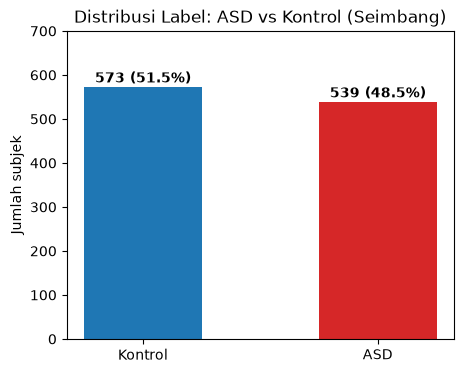

Disimpan: C:\Users\hikma\Documents\Tugas Akhir\v7\result\tabel\eda_label_per_situs.csv


Disimpan: C:\Users\hikma\Documents\Tugas Akhir\v7\result\figure\eda_label_per_situs.png


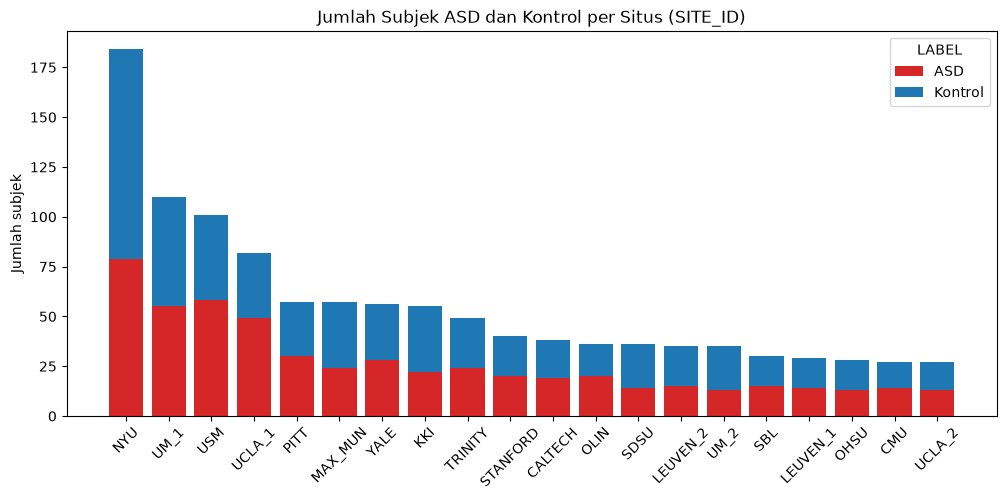

In [4]:
# 3.1 Distribusi Label Utama (DX_GROUP)
tabel_label = pheno["LABEL"].value_counts().to_frame(name="Jumlah")
tabel_label["Persen (%)"] = (pheno["LABEL"].value_counts(normalize=True) * 100).round(1)
simpan_tabel(tabel_label, "label")

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(tabel_label.index, tabel_label["Jumlah"], color=[WARNA_LABEL[l] for l in tabel_label.index], width=0.5)
ax.set_ylabel("Jumlah subjek")
ax.set_title("Distribusi Label: ASD vs Kontrol (Seimbang)")
for i, v in enumerate(tabel_label["Jumlah"]):
    ax.text(i, v + 10, f"{v} ({tabel_label['Persen (%)'].iloc[i]}%)", ha="center", fontweight="bold")
ax.set_ylim(0, 700)
simpan_gambar(fig, "label")
plt.show()

# 3.2 Distribusi Subjek per Situs (SITE_ID) - Stacked Bar
tabel_situs = pd.crosstab(pheno["SITE_ID"], pheno["LABEL"])
tabel_situs["Total"] = tabel_situs.sum(axis=1)
tabel_situs = tabel_situs.sort_values("Total", ascending=False)
simpan_tabel(tabel_situs, "label_per_situs")

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(tabel_situs.index, tabel_situs["ASD"], label="ASD", color=WARNA_LABEL["ASD"])
ax.bar(tabel_situs.index, tabel_situs["Kontrol"], bottom=tabel_situs["ASD"], label="Kontrol", color=WARNA_LABEL["Kontrol"])
ax.set_ylabel("Jumlah subjek")
ax.set_title("Jumlah Subjek ASD dan Kontrol per Situs (SITE_ID)")
ax.tick_params(axis="x", rotation=45)
ax.legend(title="LABEL")
simpan_gambar(fig, "label_per_situs")
plt.show()

## 4. Profil Karakteristik Pasien: Kebanyakan Pasien ASD Umur Berapa & IQ Berapa?

Di bagian ini kita membedah profil demografi pasien autisme (ASD) dibandingkan kelompok kontrol (TD):
1. **Kelompok Usia Pasien**: Di rentang umur mana subjek ASD paling banyak discan?
2. **Kategori Skor IQ**: Bagaimana sebaran tingkat IQ total (FIQ), verbal (VIQ), dan performa (PIQ)?
3. **Rasio Jenis Kelamin**: Bagaimana perbandingan laki-laki vs perempuan pada ASD?
4. **Tangan Dominan & Kondisi Mata saat Scan**.

In [5]:
# 4.1 Pembagian Kelompok Usia (Kategori Perkembangan)
# Kategori: Anak-anak (<12 thn), Remaja (12-18 thn), Dewasa Muda (18-30 thn), Dewasa (>30 thn)
bins_umur = [0, 12, 18, 30, 100]
labels_umur = ["Anak-anak (<12 thn)", "Remaja (12-18 thn)", "Dewasa Muda (18-30 thn)", "Dewasa (>30 thn)"]
pheno["KELOMPOK_UMUR"] = pd.cut(pheno["AGE_AT_SCAN"], bins=bins_umur, labels=labels_umur, right=False)

tabel_umur_kat = pd.crosstab(pheno["KELOMPOK_UMUR"], pheno["LABEL"])
tabel_umur_kat["Total"] = tabel_umur_kat.sum(axis=1)
tabel_umur_kat["% ASD di Usia ini"] = (tabel_umur_kat["ASD"] / tabel_umur_kat["ASD"].sum() * 100).round(1)
tabel_umur_kat["% Kontrol di Usia ini"] = (tabel_umur_kat["Kontrol"] / tabel_umur_kat["Kontrol"].sum() * 100).round(1)
simpan_tabel(tabel_umur_kat, "profil_kelompok_umur")
print("=== DISTRIBUSI KELOMPOK UMUR PASIEN ASD VS KONTROL ===")
display(tabel_umur_kat)

# 4.2 Pembagian Kategori IQ Total (FIQ)
# Kategori Klinis Standar: <70 (Intellectual Disability/Rendah), 70-84 (Borderline), 85-115 (Rata-rata/Normal), >115 (Tinggi/Superior)
bins_iq = [0, 70, 85, 115, 200]
labels_iq = ["Rendah (<70)", "Borderline (70-84)", "Rata-rata Normal (85-115)", "Tinggi / Superior (>115)"]
pheno["KATEGORI_IQ"] = pd.cut(pheno["FIQ"], bins=bins_iq, labels=labels_iq, right=False)

tabel_iq_kat = pd.crosstab(pheno["KATEGORI_IQ"], pheno["LABEL"])
tabel_iq_kat["Total"] = tabel_iq_kat.sum(axis=1)
tabel_iq_kat["% ASD di IQ ini"] = (tabel_iq_kat["ASD"] / tabel_iq_kat["ASD"].sum() * 100).round(1)
tabel_iq_kat["% Kontrol di IQ ini"] = (tabel_iq_kat["Kontrol"] / tabel_iq_kat["Kontrol"].sum() * 100).round(1)
simpan_tabel(tabel_iq_kat, "profil_kategori_iq")
print("\n=== DISTRIBUSI KATEGORI IQ (FIQ) PASIEN ASD VS KONTROL ===")
display(tabel_iq_kat)

# 4.3 Rekapitulasi Rata-rata Skor IQ Subkomponen (FIQ, VIQ, PIQ)
rekap_iq_detail = pheno.groupby("LABEL")[["FIQ", "VIQ", "PIQ"]].agg(["mean", "std", "min", "median", "max"]).round(1)
simpan_tabel(rekap_iq_detail, "rekap_iq_detail")
print("\n=== STATISTIK IQ TOTAL (FIQ), VERBAL (VIQ), DAN PERFORMA (PIQ) ===")
display(rekap_iq_detail)

Disimpan: C:\Users\hikma\Documents\Tugas Akhir\v7\result\tabel\eda_profil_kelompok_umur.csv
=== DISTRIBUSI KELOMPOK UMUR PASIEN ASD VS KONTROL ===


LABEL,ASD,Kontrol,Total,% ASD di Usia ini,% Kontrol di Usia ini
KELOMPOK_UMUR,,,,,
Anak-anak (<12 thn),155,153,308,28.8,26.7
Remaja (12-18 thn),219,235,454,40.6,41.0
Dewasa Muda (18-30 thn),117,142,259,21.7,24.8
Dewasa (>30 thn),48,43,91,8.9,7.5


Disimpan: C:\Users\hikma\Documents\Tugas Akhir\v7\result\tabel\eda_profil_kategori_iq.csv

=== DISTRIBUSI KATEGORI IQ (FIQ) PASIEN ASD VS KONTROL ===


LABEL,ASD,Kontrol,Total,% ASD di IQ ini,% Kontrol di IQ ini
KATEGORI_IQ,,,,,
Rendah (<70),6,0,6,1.2,0.0
Borderline (70-84),52,11,63,10.3,2.1
Rata-rata Normal (85-115),299,319,618,59.2,59.6
Tinggi / Superior (>115),148,205,353,29.3,38.3


Disimpan: C:\Users\hikma\Documents\Tugas Akhir\v7\result\tabel\eda_rekap_iq_detail.csv

=== STATISTIK IQ TOTAL (FIQ), VERBAL (VIQ), DAN PERFORMA (PIQ) ===


FIQ                              VIQ                            \
          mean   std   min median    max   mean   std   min median    max   
LABEL                                                                       
ASD      105.3  17.0  41.0  105.0  148.0  104.0  18.1  42.0  103.5  180.0   
Kontrol  111.2  12.3  73.0  111.0  148.0  111.5  13.2  67.0  112.0  147.0   

           PIQ                            
          mean   std   min median    max  
LABEL                                     
ASD      105.1  17.1  37.0  106.0  157.0  
Kontrol  108.1  13.2  67.0  108.0  155.0

Disimpan: C:\Users\hikma\Documents\Tugas Akhir\v7\result\figure\eda_profil_mendalam_pasien.png


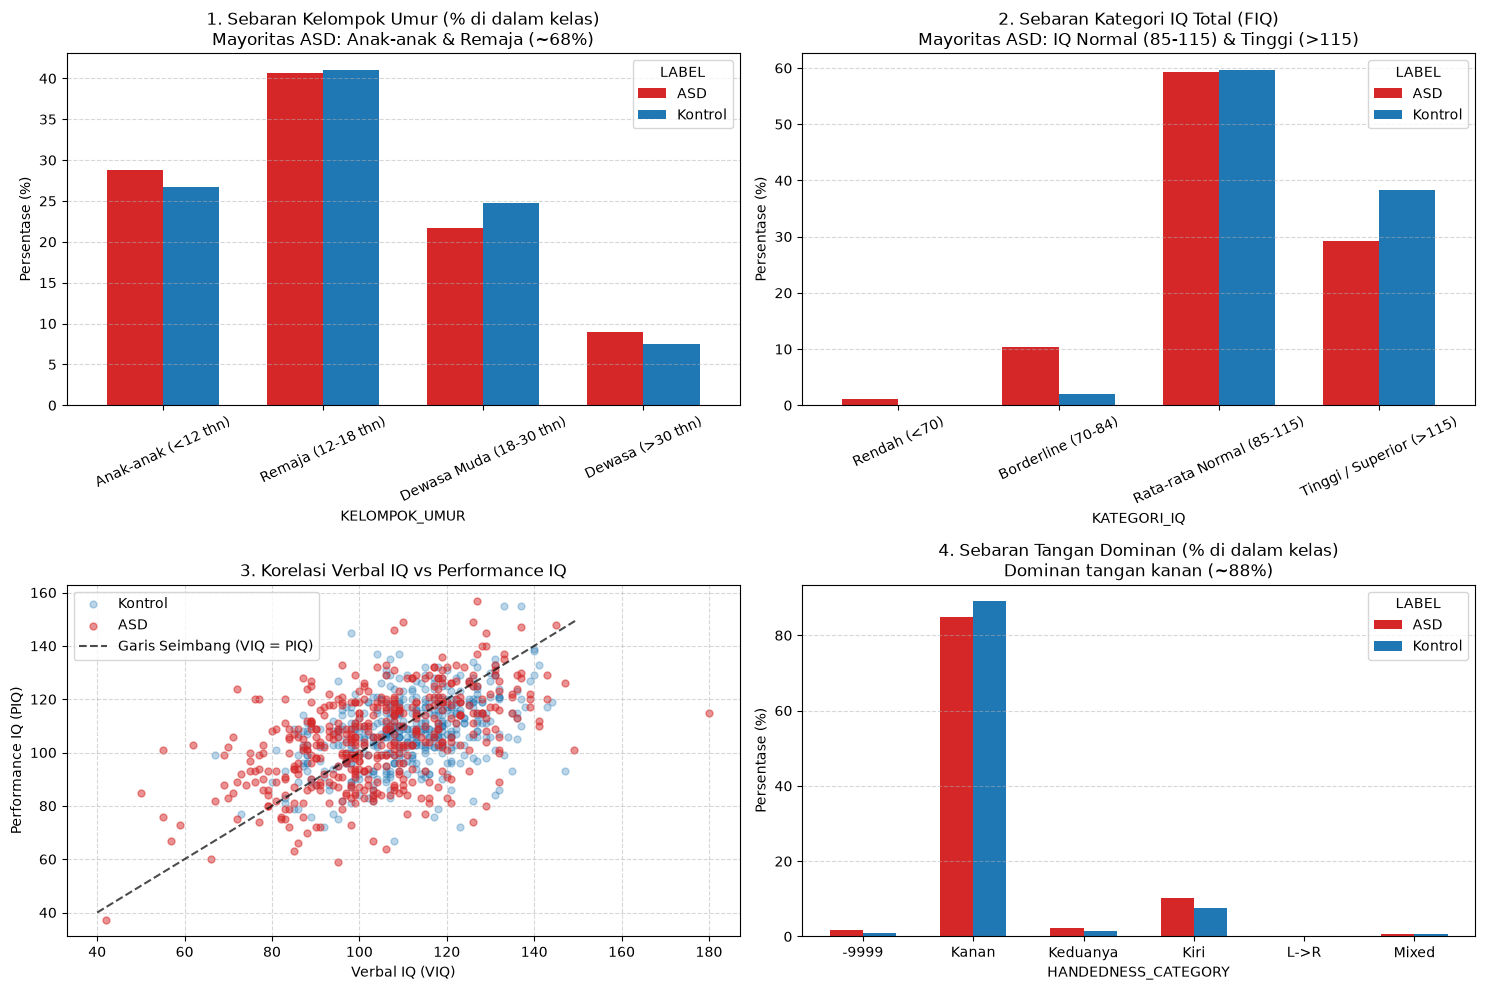

In [6]:
# Visualisasi Profil Lengkap: Umur, IQ, Gender, & Tangan Dominan
fig, axs = plt.subplots(2, 2, figsize=(15, 10))

# Plot 1: Kelompok Umur
prop_umur = pd.crosstab(pheno["KELOMPOK_UMUR"], pheno["LABEL"], normalize="columns") * 100
prop_umur.plot(kind="bar", color=[WARNA_LABEL["ASD"], WARNA_LABEL["Kontrol"]], ax=axs[0, 0], width=0.7)
axs[0, 0].set_title("1. Sebaran Kelompok Umur (% di dalam kelas)\nMayoritas ASD: Anak-anak & Remaja (~68%)")
axs[0, 0].set_ylabel("Persentase (%)")
axs[0, 0].tick_params(axis="x", rotation=25)
axs[0, 0].grid(axis="y", linestyle="--", alpha=0.5)

# Plot 2: Kategori IQ
prop_iq = pd.crosstab(pheno["KATEGORI_IQ"], pheno["LABEL"], normalize="columns") * 100
prop_iq.plot(kind="bar", color=[WARNA_LABEL["ASD"], WARNA_LABEL["Kontrol"]], ax=axs[0, 1], width=0.7)
axs[0, 1].set_title("2. Sebaran Kategori IQ Total (FIQ)\nMayoritas ASD: IQ Normal (85-115) & Tinggi (>115)")
axs[0, 1].set_ylabel("Persentase (%)")
axs[0, 1].tick_params(axis="x", rotation=25)
axs[0, 1].grid(axis="y", linestyle="--", alpha=0.5)

# Plot 3: Disparitas VIQ (Verbal) vs PIQ (Performance) pada Pasien ASD
ax3 = axs[1, 0]
iq_valid = pheno.dropna(subset=["VIQ", "PIQ"])
ax3.scatter(iq_valid.loc[iq_valid["LABEL"] == "Kontrol", "VIQ"], 
            iq_valid.loc[iq_valid["LABEL"] == "Kontrol", "PIQ"], 
            color=WARNA_LABEL["Kontrol"], alpha=0.3, label="Kontrol", s=25)
ax3.scatter(iq_valid.loc[iq_valid["LABEL"] == "ASD", "VIQ"], 
            iq_valid.loc[iq_valid["LABEL"] == "ASD", "PIQ"], 
            color=WARNA_LABEL["ASD"], alpha=0.5, label="ASD", s=25)
ax3.plot([40, 150], [40, 150], "k--", alpha=0.7, label="Garis Seimbang (VIQ = PIQ)")
ax3.set_xlabel("Verbal IQ (VIQ)")
ax3.set_ylabel("Performance IQ (PIQ)")
ax3.set_title("3. Korelasi Verbal IQ vs Performance IQ")
ax3.legend()
ax3.grid(True, linestyle="--", alpha=0.5)

# Plot 4: Tangan Dominan (Handedness)
tabel_hand = pd.crosstab(pheno["HANDEDNESS_CATEGORY"].replace({"Ambi": "Keduanya", "L": "Kiri", "R": "Kanan"}), pheno["LABEL"], normalize="columns") * 100
tabel_hand.plot(kind="bar", color=[WARNA_LABEL["ASD"], WARNA_LABEL["Kontrol"]], ax=axs[1, 1], width=0.6)
axs[1, 1].set_title("4. Sebaran Tangan Dominan (% di dalam kelas)\nDominan tangan kanan (~88%)")
axs[1, 1].set_ylabel("Persentase (%)")
axs[1, 1].tick_params(axis="x", rotation=0)
axs[1, 1].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
simpan_gambar(fig, "profil_mendalam_pasien")
plt.show()

## 5. Analisis Data Kosong (*Missing Values*) per Kolom

Mengevaluasi seberapa lengkap masing-masing kolom dari total 75 kolom.

Disimpan: C:\Users\hikma\Documents\Tugas Akhir\v7\result\tabel\eda_persen_kosong_per_kolom.csv


Disimpan: C:\Users\hikma\Documents\Tugas Akhir\v7\result\figure\eda_persen_kosong_per_kolom.png


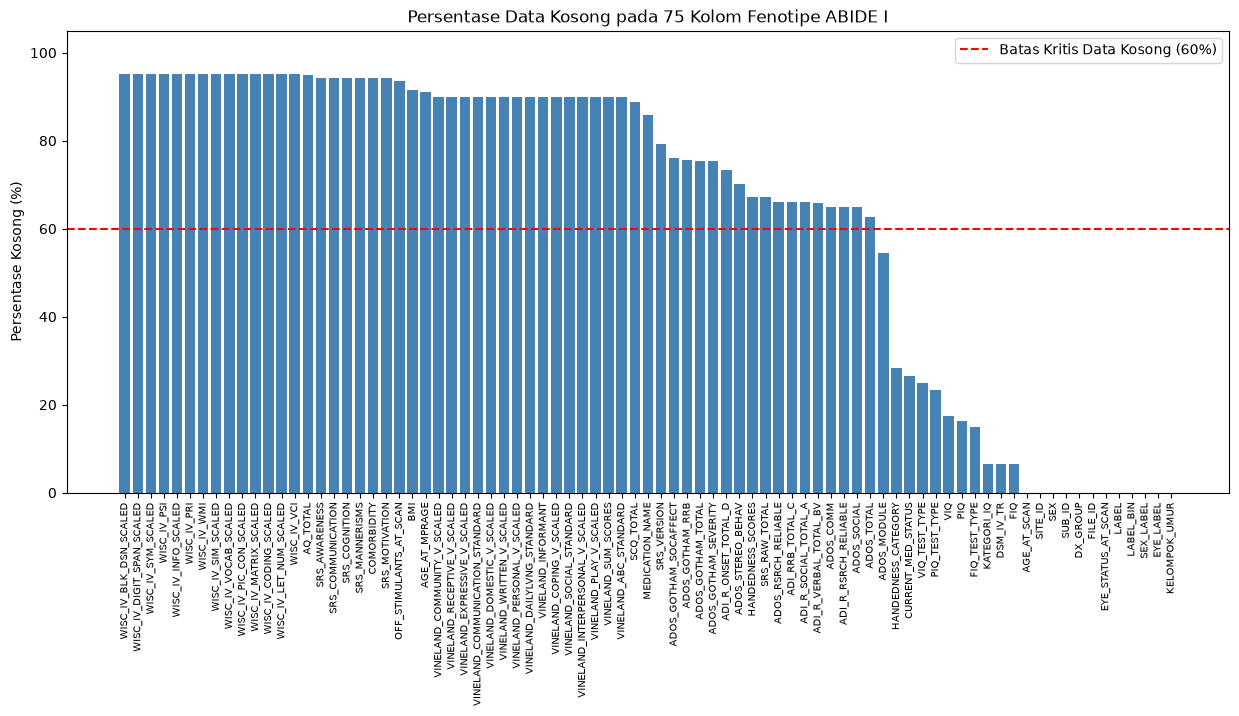

Jumlah kolom dengan data kosong > 60%: 58 kolom dari 75 kolom


In [7]:
persen_kosong = (pheno.isna().mean() * 100).sort_values(ascending=False)
simpan_tabel(persen_kosong.to_frame(name="Persen_Kosong"), "persen_kosong_per_kolom")

fig, ax = plt.subplots(figsize=(15, 6))
ax.bar(persen_kosong.index, persen_kosong.values, color="steelblue", width=0.8)
ax.axhline(60, color="red", linestyle="--", label="Batas Kritis Data Kosong (60%)")
ax.set_ylabel("Persentase Kosong (%)")
ax.set_title("Persentase Data Kosong pada 75 Kolom Fenotipe ABIDE I")
ax.tick_params(axis="x", rotation=90, labelsize=7)
ax.set_ylim(0, 105)
ax.legend()
simpan_gambar(fig, "persen_kosong_per_kolom")
plt.show()

print(f"Jumlah kolom dengan data kosong > 60%: {(persen_kosong > 60).sum()} kolom dari 75 kolom")

## 6. Rasionalisasi Seleksi Kolom & Pencegahan Data Leakage

### A. Mengapa Kolom Tes Klinis Autisme (`ADOS_*`, `ADI_R_*`, `SRS_*`, `DSM_IV_TR`) DIBUANG?
1. **Pencegahan *Data Leakage* (Kebocoran Jawaban):**
   * Skor `ADOS` dan `ADI-R` adalah instrumen wawancara & observasi psikiatri yang **digunakan dokter untuk menetapkan diagnosis autisme itu sendiri**.
   * Jika skor ini dimasukkan sebagai fitur input pada model AI yang bertugas memprediksi diagnosis, model akan mendapat "bocoran kunci jawaban". Akurasi klasifikasi akan tampak sangat tinggi (misal 99%), tetapi model **tidak belajar dari pola citra otak**, melainkan hanya menghafal skor tes dokter.
2. **Ketiadaan Nilai pada Kelompok Kontrol:**
   * Tes autisme (`ADOS`, `ADI-R`) hampir hanya diberikan kepada pasien yang dicurigai autisme (ASD). Kelompok kontrol sehat (TD) hampir seluruhnya bernilai `NaN`. Akibatnya, model AI cukup melihat *"apakah ada nilainya atau tidak"* untuk langsung menebak label dengan benar tanpa memproses fitur neuroimaging.

---

### B. Mengapa Kolom Tes Tambahan & Medis DIBUANG?
* Kolom seperti `VINELAND_*`, `WISC_IV_*`, `COMORBIDITY`, dan `MEDICATION_NAME` memiliki tingkat **data kosong ekstrim (>60% hingga 95%)** karena hanya diukur oleh 2–3 situs pengumpul. Kolom ini tidak dapat diimputasi dengan andal dan merusak matriks fitur.

---

### C. Mengapa Hanya 19 Kolom Ini yang DIPERTAHANKAN?
Hanya **19 kolom terpilih** yang disimpan untuk tahap selanjutnya:
1. **Identitas & Relasi Citra (5 kolom):** `SITE_ID`, `RAW_FOLDER`, `SUB_ID`, `SUB_ID_STR`, `FILE_ID` $\rightarrow$ Kunci relasi menghubungkan tabel ke folder citra NIfTI dan PCP.
2. **Label Target Ground Truth (3 kolom):** `DX_GROUP`, `LABEL`, `LABEL_BIN` (1 = ASD, 0 = Kontrol) $\rightarrow$ Label target untuk evaluasi model.
3. **Kovariat Demografi Sah (7 kolom):** `AGE_AT_SCAN`, `SEX`, `SEX_LABEL`, `HANDEDNESS_CATEGORY`, `FIQ`, `VIQ`, `PIQ` $\rightarrow$ Karakteristik biologis dan kognitif umum yang tidak membocorkan diagnosis autisme dan sah digunakan untuk analisis kovariat / matching.
4. **Metadata Protokol Scan (2 kolom):** `EYE_STATUS_AT_SCAN`, `EYE_STATUS_LABEL` $\rightarrow$ Mengontrol variasi sinyal visual rs-fMRI (mata terbuka vs tertutup).
5. **Integritas Modalitas (2 kolom):** `HAS_RAW_FMRI`, `HAS_RAW_SMRI` $\rightarrow$ Verifikasi ketersediaan file citra sebelum pemodelan.

In [8]:
ringkasan_seleksi = pd.DataFrame({
    "Kategori": [
        "Identitas & Relasi Citra",
        "Label Target Sah",
        "Kovariat Demografi Sah",
        "Karakteristik Kognitif (IQ)",
        "Metadata Protokol Scan",
        "DIBUANG: Skor Tes Klinis (Data Leakage)",
        "DIBUANG: Tes Tambahan (>60% Kosong)"
    ],
    "Jumlah Kolom": [5, 3, 4, 3, 2, 28, 30],
    "Status": ["Dipertahankan", "Dipertahankan", "Dipertahankan", "Dipertahankan", "Dipertahankan", "Dieliminasi (Leakage)", "Dieliminasi (Missing)"],
    "Contoh Kolom": [
        "SITE_ID, SUB_ID, FILE_ID",
        "DX_GROUP, LABEL, LABEL_BIN",
        "AGE_AT_SCAN, SEX, HANDEDNESS",
        "FIQ, VIQ, PIQ",
        "EYE_STATUS_AT_SCAN",
        "ADOS_TOTAL, ADI_R_SOCIAL, SRS_RAW",
        "VINELAND_*, WISC_IV_*, MEDICATION"
    ]
})

print("Rangkuman Rasionalisasi Seleksi Kolom Fenotipe:")
display(ringkasan_seleksi)

Rangkuman Rasionalisasi Seleksi Kolom Fenotipe:


,Kategori,Jumlah Kolom,Status,Contoh Kolom
0,Identitas & Relasi Citra,5,Dipertahankan,"SITE_ID, SUB_ID, FILE_ID"
1,Label Target Sah,3,Dipertahankan,"DX_GROUP, LABEL, LABEL_BIN"
2,Kovariat Demografi Sah,4,Dipertahankan,"AGE_AT_SCAN, SEX, HANDEDNESS"
3,Karakteristik Kognitif (IQ),3,Dipertahankan,"FIQ, VIQ, PIQ"
4,Metadata Protokol Scan,2,Dipertahankan,EYE_STATUS_AT_SCAN
5,DIBUANG: Skor Tes Klinis (Data Leakage),28,Dieliminasi (Leakage),"ADOS_TOTAL, ADI_R_SOCIAL, SRS_RAW"
6,DIBUANG: Tes Tambahan (>60% Kosong),30,Dieliminasi (Missing),"VINELAND_*, WISC_IV_*, MEDICATION"


## 7. Pencocokan Subjek Fenotipe dengan Citra Mentah (`data/raw/`)

Memetakan ketersediaan file sMRI (`mprage.nii.gz`) dan rs-fMRI (`rest.nii.gz`) pada folder disk.

In [9]:
# Format SUB_ID_STR (7 digit)
pheno["SUB_ID_STR"] = pheno["SUB_ID"].astype(str).str.zfill(7)

# Cek file raw di folder
subjek_di_raw = {}
if RAW_DIR.exists():
    for site_folder in RAW_DIR.iterdir():
        if site_folder.is_dir():
            for sub_folder in site_folder.iterdir():
                if sub_folder.is_dir() and sub_folder.name != "9999999":
                    sub_id = sub_folder.name
                    has_f = (sub_folder / "session_1" / "rest_1" / "rest.nii.gz").exists()
                    has_s = (sub_folder / "session_1" / "anat_1" / "mprage.nii.gz").exists()
                    subjek_di_raw[sub_id] = {
                        "site_folder": site_folder.name,
                        "has_fmri": has_f,
                        "has_smri": has_s
                    }

has_fmri = [subjek_di_raw.get(sid, {}).get("has_fmri", False) for sid in pheno["SUB_ID_STR"]]
has_smri = [subjek_di_raw.get(sid, {}).get("has_smri", False) for sid in pheno["SUB_ID_STR"]]

pheno["HAS_RAW_FMRI"] = has_fmri
pheno["HAS_RAW_SMRI"] = has_smri

tabel_status_raw = pd.crosstab(
    pheno["HAS_RAW_SMRI"].map({True: "Punya sMRI", False: "Tanpa sMRI"}),
    pheno["HAS_RAW_FMRI"].map({True: "Punya fMRI", False: "Tanpa fMRI"}),
    margins=True, margins_name="Total"
)
simpan_tabel(tabel_status_raw, "status_data_raw")
print("Status Ketersediaan Citra Raw pada 1.112 Subjek Fenotipe:")
display(tabel_status_raw)

Disimpan: C:\Users\hikma\Documents\Tugas Akhir\v7\result\tabel\eda_status_data_raw.csv
Status Ketersediaan Citra Raw pada 1.112 Subjek Fenotipe:


HAS_RAW_FMRI,Punya fMRI,Tanpa fMRI,Total
HAS_RAW_SMRI,,,
Punya sMRI,1097,0,1097
Tanpa sMRI,10,5,15
Total,1107,5,1112
